In [1]:
!pip install -q textblob vaderSentiment wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.6 MB/s eta 0:00:00


In [2]:
import nltk
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'brown']:
    nltk.download(p)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Cleaned: football is the most popular sport in the world and i have loved it since childhood every weekend millions of fans gather in stadiums and in front of their televisions to watch their favourite teams play a single goal can change the mood of an entire city within seconds players train for years to improve their speed passing and teamwork modern football also uses technology like var and data analytics to make the game fairer and smarter for me football isnt just a game it teaches discipline patience and the value of working together
Sentences: ['Football is the most popular sport in the world, and I have loved it since childhood.', 'Every weekend, millions of fans gather in stadiums and in front of their televisions to watch their favourite teams play.', 'A single goal can change the mood of an entire city within seconds!', 'Players train for years to improve their speed, passing and teamwork.', 'Modern football also uses technology like VAR and data analytics to make the game 

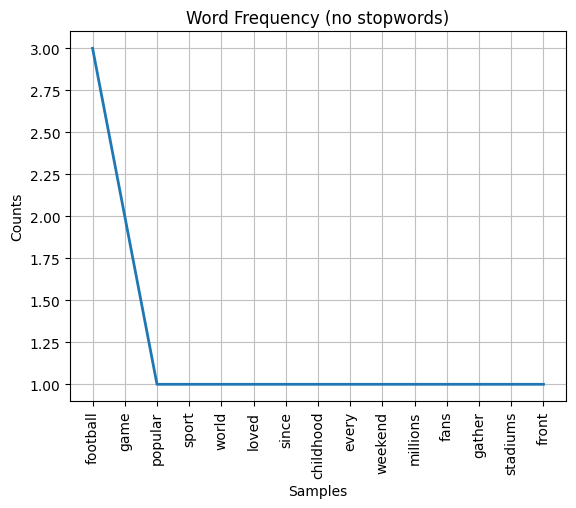

In [3]:
import re, nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk import FreqDist
import matplotlib.pyplot as plt

for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(p)

text = ("Football is the most popular sport in the world, and I have loved it since childhood. "
        "Every weekend, millions of fans gather in stadiums and in front of their televisions to watch their favourite teams play. "
        "A single goal can change the mood of an entire city within seconds! "
        "Players train for years to improve their speed, passing and teamwork. "
        "Modern football also uses technology like VAR and data analytics to make the game fairer and smarter. "
        "For me, football isn't just a game, it teaches discipline, patience and the value of working together.")

# 1. Lowercase + remove punctuation using re
clean = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned:", clean)

# 2. Tokenize into sentences and words
print("Sentences:", sent_tokenize(text))
print("Words:", word_tokenize(clean))

# 3. split() vs word_tokenize()  (on the original text to see the difference)
print("split():        ", text.split()[:15])
print("word_tokenize():", word_tokenize(text)[:15])
print("Contraction ->", "isn't".split(), word_tokenize("isn't"))

# 4. Remove stopwords
stop = set(stopwords.words('english'))
filtered = [w for w in word_tokenize(clean) if w not in stop]
print("Without stopwords:", filtered)

# 5. Frequency distribution
fd = FreqDist(filtered)
print(fd.most_common(10))
fd.plot(15, title="Word Frequency (no stopwords)")
plt.show()

QUESTION 2

In [4]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Only alphabetic words
words = re.findall(r'[a-zA-Z]+', text.lower())

# 2. Remove stopwords
stop = set(stopwords.words('english'))
words = [w for w in words if w not in stop]

# 3.
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in words]

# 4.
wl = WordNetLemmatizer()
lemmatized = [wl.lemmatize(w) for w in words]            # default noun
lemmatized_v = [wl.lemmatize(w, pos='v') for w in words] # verb

# 5. Compare
import pandas as pd
print(pd.DataFrame({'Original': words, 'Stemmed': stemmed,
                    'Lemma(noun)': lemmatized, 'Lemma(verb)': lemmatized_v}).to_string())

       Original    Stemmed Lemma(noun)  Lemma(verb)
0      football    footbal    football     football
1       popular    popular     popular      popular
2         sport      sport       sport        sport
3         world      world       world        world
4         loved       love       loved         love
5         since       sinc       since        since
6     childhood  childhood   childhood    childhood
7         every      everi       every        every
8       weekend    weekend     weekend      weekend
9      millions    million     million     millions
10         fans        fan         fan          fan
11       gather     gather      gather       gather
12     stadiums    stadium     stadium     stadiums
13        front      front       front        front
14  televisions    televis  television  televisions
15        watch      watch       watch        watch
16    favourite   favourit   favourite    favourite
17        teams       team        team         team
18         p

i would prefer stemming for search engines, indexing, and large datasets where speed matters more than readable output and lemmatization for sentiment analysis, chatbots, text generation, and anywhere meaning and readable words matter.

QUESTION 3

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd, numpy as np

texts = [
    "The new smartphone has an amazing camera and a very long battery life",
    "Stock markets fell sharply today as investors worried about rising inflation",
    "The team won the championship after a thrilling final match last night",
]

# 1. Bag of Words
cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

# 2. TF-IDF
tv = TfidfVectorizer(stop_words='english')
tfidf = tv.fit_transform(texts)
features = tv.get_feature_names_out()
print(pd.DataFrame(tfidf.toarray().round(3), columns=features))

# 3. Top 3 keywords per text
for i, row in enumerate(tfidf.toarray()):
    top = np.argsort(row)[::-1][:3]
    print(f"Text {i+1}:", [(features[j], round(row[j], 3)) for j in top])

   amazing  battery  camera  championship  fell  final  inflation  investors  \
0        1        1       1             0     0      0          0          0   
1        0        0       0             0     1      0          1          1   
2        0        0       0             1     0      1          0          0   

   life  long  ...  night  rising  sharply  smartphone  stock  team  \
0     1     1  ...      0       0        0           1      0     0   
1     0     0  ...      0       1        1           0      1     0   
2     0     0  ...      1       0        0           0      0     1   

   thrilling  today  won  worried  
0          0      0    0        0  
1          0      1    0        1  
2          1      0    1        0  

[3 rows x 23 columns]
   amazing  battery  camera  championship   fell  final  inflation  investors  \
0    0.378    0.378   0.378         0.000  0.000  0.000      0.000      0.000   
1    0.000    0.000   0.000         0.000  0.333  0.000      0.33

QUESTION 4

In [6]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

t1 = ("Artificial intelligence enables machines to learn from data and make decisions. "
      "It is used in healthcare, finance and self-driving cars. "
      "Machine learning models improve as they process more data. "
      "AI systems can analyze images, text and speech.")
t2 = ("Blockchain is a decentralized digital ledger that records transactions securely. "
      "Each block is linked to the previous one using cryptography. "
      "It is used in cryptocurrency, finance and supply chains. "
      "Data stored on a blockchain cannot easily be altered.")

stop = set(stopwords.words('english'))
def prep(t):
    return [w for w in word_tokenize(re.sub(r'[^\w\s]', ' ', t.lower())) if w not in stop]

tok1, tok2 = prep(t1), prep(t2)
print(tok1, tok2, sep="\n")

# a. Jaccard
s1, s2 = set(tok1), set(tok2)
jaccard = len(s1 & s2) / len(s1 | s2)
print("Common words:", s1 & s2)
print("Jaccard:", round(jaccard, 4))

# b. Cosine with TF-IDF
tfidf = TfidfVectorizer(stop_words='english').fit_transform([t1, t2])
print("Cosine:", round(cosine_similarity(tfidf[0], tfidf[1])[0][0], 4))

['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'make', 'decisions', 'used', 'healthcare', 'finance', 'self', 'driving', 'cars', 'machine', 'learning', 'models', 'improve', 'process', 'data', 'ai', 'systems', 'analyze', 'images', 'text', 'speech']
['blockchain', 'decentralized', 'digital', 'ledger', 'records', 'transactions', 'securely', 'block', 'linked', 'previous', 'one', 'using', 'cryptography', 'used', 'cryptocurrency', 'finance', 'supply', 'chains', 'data', 'stored', 'blockchain', 'easily', 'altered']
Common words: {'finance', 'data', 'used'}
Jaccard: 0.0682
Cosine: 0.0853


Q4 C ) Jaccard only checks which words are shared, so every word counts equally and frequency is ignored. Cosine with TF-IDF weights words by importance, so shared generic words (used, finance, data) count for less than distinctive ones, and repeated terms are accounted for. Cosine similarity is the better metric here. Both texts are about different technologies and both scores will come out low, but cosine gives a more nuanced and reliable value, especially for longer texts.

QUESTION 5

                                             Review  TB Polarity  TB Subjectivity   VADER     Label
0  Absolutely love this phone, the camera is fan...        0.500            0.750  0.8550  Positive
1  Terrible service, the delivery was late and t...       -0.650            0.800 -0.7184  Negative
2  The product is okay, it works as described bu...        0.429            0.536 -0.3479  Negative
3  Excellent quality and great value for money, ...        0.667            0.763  0.9115  Positive
4  Very disappointed, the item stopped working a...       -0.975            0.975 -0.6478  Negative
5  Amazing customer support, they solved my prob...        0.467            0.700  0.7096  Positive


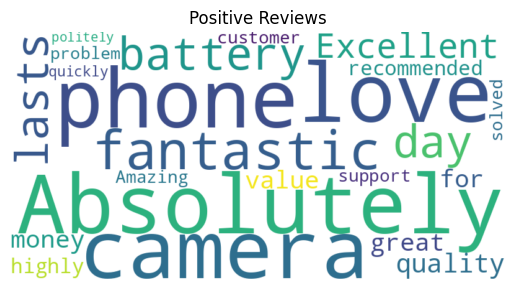

In [7]:
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import matplotlib.pyplot as plt, pandas as pd

reviews = [
    "Absolutely love this phone, the camera is fantastic and the battery lasts all day!",
    "Terrible service, the delivery was late and the package was damaged.",
    "The product is okay, it works as described but nothing special.",
    "Excellent quality and great value for money, highly recommended!",
    "Very disappointed, the item stopped working after two days.",
    "Amazing customer support, they solved my problem quickly and politely.",
]

vader = SentimentIntensityAnalyzer()
rows = []
for r in reviews:
    tb = TextBlob(r)
    comp = vader.polarity_scores(r)['compound']
    label = "Positive" if comp >= 0.05 else "Negative" if comp <= -0.05 else "Neutral"
    rows.append([r[:45] + "...", round(tb.sentiment.polarity, 3),
                 round(tb.sentiment.subjectivity, 3), comp, label])

df = pd.DataFrame(rows, columns=['Review', 'TB Polarity', 'TB Subjectivity', 'VADER', 'Label'])
print(df.to_string())

# Word cloud of positive reviews
pos_text = " ".join(r for r, l in zip(reviews, df['Label']) if l == "Positive")
wc = WordCloud(width=800, height=400, background_color='white', stopwords={'the','and','this','is','all','my','they'}).generate(pos_text)
plt.imshow(wc, interpolation='bilinear'); plt.axis('off'); plt.title("Positive Reviews"); plt.show()

QUESTION 6

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical


try:
    from tensorflow.keras.preprocessing.text import Tokenizer
except Exception:
    try:
        from keras.preprocessing.text import Tokenizer
    except Exception:
        from keras.src.legacy.preprocessing.text import Tokenizer


try:
    from tensorflow.keras.preprocessing.sequence import pad_sequences
except Exception:
    from tensorflow.keras.utils import pad_sequences

data = ("football is a game of skill and teamwork. players train hard every day to improve their speed and passing. "
        "fans fill the stadium to cheer for their team. a single goal can bring joy to millions of people. "
        "the coach plans the strategy and the players follow it on the field. "
        "football teaches discipline patience and the value of working together. "
        "every match is a new chance to learn and to win.")

# ---------- 1. Tokenize ----------
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])
vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)
print("Word index sample:", dict(list(tokenizer.word_index.items())[:10]))


sequences = []
for line in data.split('.'):
    line = line.strip()
    if not line:
        continue
    ids = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(ids) + 1):
        sequences.append(ids[:i])

max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding='pre')

X = sequences[:, :-1]
y = to_categorical(sequences[:, -1], num_classes=vocab_size)
print("Total sequences:", len(sequences), "| Max length:", max_len)

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=50),
    LSTM(100),
    Dense(vocab_size, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build(input_shape=(None, max_len - 1))
model.summary()

# ---------- 3. Train ----------
history = model.fit(X, y, epochs=300, verbose=0)
print("Final training accuracy:", round(history.history['accuracy'][-1], 4))

def generate_text(seed_word, next_words=8):
    result = seed_word.lower()
    for _ in range(next_words):
        ids = tokenizer.texts_to_sequences([result])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding='pre')
        predicted = int(np.argmax(model.predict(ids, verbose=0), axis=-1)[0])
        word = tokenizer.index_word.get(predicted, "")
        if word == "":
            break
        result += " " + word
    return result

for seed in ["football", "players", "every"]:
    print(generate_text(seed))

Vocabulary size: 51
Word index sample: {'the': 1, 'and': 2, 'to': 3, 'a': 4, 'of': 5, 'football': 6, 'is': 7, 'players': 8, 'every': 9, 'their': 10}
Total sequences: 65 | Max length: 13


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 12, 50)         │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        60,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 51)             │         5,151 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,101 (266.02 KB)

 Trainable params: 68,101 (266.02 KB)

 Non-trainable params: 0 (0.00 B)

Final training accuracy: 0.9692
football is a game of skill and teamwork teamwork
players train hard every day to improve their speed
every match is a new chance to learn and
